# Experiment 22 · LeNet-5 Forward Pass

The `cnn` package adds four image layers — `Pad`, `Conv2D`, `MaxPool2D` and `Flatten` — that work
on one image at a time, shaped `(channels, rows, cols)`. The `lenet5` package stacks them with two
`numpy_nn` dense layers into LeNet-5. This notebook checks each building block by hand, traces an
MNIST digit through the whole network, and runs the four sanity checks from `lenet5testing`.

The network is **untrained**: every weight is drawn from `[-0.05, 0.05]` and every bias is zero.
So the goal here is not accuracy but a forward pass that is correct in shape, deterministic, and
always ends in a valid probability distribution.

| Layer | Operation | Output shape |
|---|---|---|
| input | MNIST digit, pixels scaled to 0–1 | (1, 28, 28) |
| pad | 2 zeros on every side | (1, 32, 32) |
| C1 | 6 kernels 5×5, stride 1, ReLU | (6, 28, 28) |
| S2 | max pool 2×2, stride 2 | (6, 14, 14) |
| C3 | 16 kernels 5×5×6, stride 1, ReLU | (16, 10, 10) |
| S4 | max pool 2×2, stride 2 | (16, 5, 5) |
| C5 | 120 kernels 5×5×16, stride 1, ReLU | (120, 1, 1) |
| flatten | | (120,) |
| F6 | dense, ReLU | (84,) |
| output | dense, softmax | (10,) |

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# the repository root is the first folder above this notebook that holds pyproject.toml
REPO_ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "pyproject.toml").exists())
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

from cnn import Conv2D, Flatten, MaxPool2D, Pad
from cnn.utils import windows_fast, windows_loop
from lenet5 import LeNet5, lenet5testing
from mnist import plot_images, plot_predictions, read_images, read_labels
from numpy_utils import ACTIVATIONS

DATA_DIR = REPO_ROOT / "data" / "mnist"
SEED = 42

## Building blocks

Every layer takes and returns a single image `(channels, rows, cols)` — there is no batch axis yet.
Each one is checked on a tiny input small enough to verify by eye.

### Pad

`Pad(amount)` surrounds every channel with `amount` rows and columns of zeros. LeNet-5 pads the
28×28 MNIST digits to 32×32 so the first 5×5 convolution keeps the output at 28×28.

In [2]:
tiny = np.arange(1, 10, dtype=float).reshape(1, 3, 3)
padded = Pad(amount=1).forward(tiny)

print("input", tiny.shape)
print(tiny[0])
print("\npadded", padded.shape)
print(padded[0])

input (1, 3, 3)
[[1. 2. 3.]
 [4. 5. 6.]
 [7. 8. 9.]]

padded (1, 5, 5)
[[0. 0. 0. 0. 0.]
 [0. 1. 2. 3. 0.]
 [0. 4. 5. 6. 0.]
 [0. 7. 8. 9. 0.]
 [0. 0. 0. 0. 0.]]


### Sliding windows

Both convolution and pooling look at every `window_rows × window_cols` patch of the input.
`cnn.utils` builds all patches at once as an array shaped
`(channels, window_rows, window_cols, out_rows, out_cols)`, so `[..., r, c]` is the patch that
produces output pixel `(r, c)`. Along each axis there are `(size - window) // stride + 1` patches.

There are two implementations:

- `windows_loop` copies the patches into a new array, one window offset at a time.
- `windows_fast` copies nothing: `as_strided` returns a read-only *view* of the input whose strides
  step through memory so that each patch appears as its own slice.

They must agree exactly.

In [3]:
grid = np.arange(16, dtype=float).reshape(1, 4, 4)
fast = windows_fast(grid, window_rows=2, window_cols=2, stride=2)
loop = windows_loop(grid, window_rows=2, window_cols=2, stride=2)

print("input")
print(grid[0])
print("\nwindows shape:", fast.shape)
for r in range(fast.shape[3]):
    for c in range(fast.shape[4]):
        print(f"patch for output ({r}, {c}):", fast[0, :, :, r, c].tolist())

print("\nloop and fast agree:", np.array_equal(fast, loop))
print("fast shares memory with input:", np.shares_memory(fast, grid))

input
[[ 0.  1.  2.  3.]
 [ 4.  5.  6.  7.]
 [ 8.  9. 10. 11.]
 [12. 13. 14. 15.]]

windows shape: (1, 2, 2, 2, 2)
patch for output (0, 0): [[0.0, 1.0], [4.0, 5.0]]
patch for output (0, 1): [[2.0, 3.0], [6.0, 7.0]]
patch for output (1, 0): [[8.0, 9.0], [12.0, 13.0]]
patch for output (1, 1): [[10.0, 11.0], [14.0, 15.0]]

loop and fast agree: True
fast shares memory with input: True


The view matters at LeNet-5 scale: C1's windows of the padded digit hold 1 × 5 × 5 × 28 × 28 =
19,600 numbers that `windows_loop` must allocate and fill, while `windows_fast` only builds a header.

In [4]:
rng = np.random.default_rng(SEED)
padded_digit = rng.random((1, 32, 32))
c3_input = rng.random((6, 14, 14))


def time_per_call(function, inputs, repeats=2000):
    start = time.perf_counter()
    for _ in range(repeats):
        function(inputs, window_rows=5, window_cols=5, stride=1)
    return (time.perf_counter() - start) / repeats * 1e6


for name, inputs in [("C1 input (1, 32, 32)", padded_digit), ("C3 input (6, 14, 14)", c3_input)]:
    same = np.array_equal(windows_fast(inputs, 5, 5, 1), windows_loop(inputs, 5, 5, 1))
    loop_us = time_per_call(windows_loop, inputs)
    fast_us = time_per_call(windows_fast, inputs)
    print(f"{name}: loop {loop_us:7.1f} µs | fast {fast_us:5.1f} µs | equal: {same}")

C1 input (1, 32, 32): loop    22.3 µs | fast   3.5 µs | equal: True
C3 input (6, 14, 14): loop    27.1 µs | fast   4.0 µs | equal: True


### Conv2D

`Conv2D(weights, bias, activation, stride)` takes weights shaped
`(out_channels, in_channels, kernel_rows, kernel_cols)` and one bias per output channel shaped
`(out_channels, 1, 1)`. Each output pixel is the sum over *all* input channels of kernel × patch,
plus the bias. In code that is one `np.tensordot` over the first three axes of the weights and the
windows:

`(out, in, kr, kc) · (in, kr, kc, out_r, out_c) → (out, out_r, out_c)`

The check below uses two hand-picked kernels on the 4×4 grid from above: one sums the 2×2 patch,
the other subtracts the left column from the right column (a vertical edge detector). The identity
activation keeps negative values visible.

In [5]:
kernels = np.array([
    [[[1, 1],
      [1, 1]]],      # sum of the patch
    [[[-1, 1],
      [-1, 1]]],     # right column minus left column
], dtype=float)
bias = np.array([0.0, 0.5]).reshape(2, 1, 1)

conv = Conv2D(weights=kernels, bias=bias, activation=ACTIVATIONS.IDENTITY, stride=1)
convolved = conv.forward(grid)

# the same result, one output pixel at a time
expected = np.zeros((2, 3, 3))
for k in range(2):
    for r in range(3):
        for c in range(3):
            expected[k, r, c] = np.sum(kernels[k] * grid[:, r:r + 2, c:c + 2]) + bias[k, 0, 0]

print("output shape:", convolved.shape)
print("sum kernel:\n", convolved[0])
print("edge kernel (+0.5 bias):\n", convolved[1])
print("matches explicit loop:", np.allclose(convolved, expected))

output shape: (2, 3, 3)
sum kernel:
 [[10. 14. 18.]
 [26. 30. 34.]
 [42. 46. 50.]]
edge kernel (+0.5 bias):
 [[2.5 2.5 2.5]
 [2.5 2.5 2.5]
 [2.5 2.5 2.5]]
matches explicit loop: True


Every column of the grid increases by 1 to the right, so the edge kernel sees the same difference
(2 per patch) everywhere and outputs a constant 2 + 0.5. With `stride=2` the kernel jumps two pixels
at a time and the 3×3 output shrinks to 2×2:

In [6]:
strided = Conv2D(weights=kernels, bias=bias, activation=ACTIVATIONS.IDENTITY, stride=2).forward(grid)
print("stride 2 output shape:", strided.shape)
print(strided[0])

stride 2 output shape: (2, 2, 2)
[[10. 18.]
 [42. 50.]]


### MaxPool2D and Flatten

`MaxPool2D(pool_rows, pool_cols, stride)` takes the largest value of each window, per channel — it
has no weights. `Flatten` reshapes `(channels, rows, cols)` into one vector so the dense layers can
take over.

In [7]:
pooled = MaxPool2D(pool_rows=2, pool_cols=2, stride=2).forward(grid)
flat = Flatten().forward(pooled)

print("input\n", grid[0])
print("\nmax pooled", pooled.shape, "\n", pooled[0])
print("\nflattened", flat.shape, flat)

input
 [[ 0.  1.  2.  3.]
 [ 4.  5.  6.  7.]
 [ 8.  9. 10. 11.]
 [12. 13. 14. 15.]]

max pooled (1, 2, 2) 
 [[ 5.  7.]
 [13. 15.]]

flattened (4,) [ 5.  7. 13. 15.]


## Assembling LeNet-5

`LeNet5(seed)` draws every weight from `[-0.05, 0.05]`, sets every bias to zero and chains the
layers in forward order. The same seed always gives the same starting weights.

In [8]:
net = LeNet5(seed=SEED)

parameters = [
    ("C1", net.c1_weights, net.c1_bias),
    ("C3", net.c3_weights, net.c3_bias),
    ("C5", net.c5_weights, net.c5_bias),
    ("F6", net.f6_weights, net.f6_bias),
    ("output", net.output_weights, net.output_bias),
]

total = 0
for name, weights, bias in parameters:
    count = weights.size + bias.size
    total += count
    print(f"{name:>6}: weights {str(weights.shape):<17} bias {str(bias.shape):<12} {count:>7,} parameters")
print(f"{'total':>6}: {total:,} parameters")

    C1: weights (6, 1, 5, 5)      bias (6, 1, 1)        156 parameters
    C3: weights (16, 6, 5, 5)     bias (16, 1, 1)     2,416 parameters
    C5: weights (120, 16, 5, 5)   bias (120, 1, 1)   48,120 parameters
    F6: weights (84, 120)         bias (84,)         10,164 parameters
output: weights (10, 84)          bias (10,)            850 parameters
 total: 61,706 parameters


C5 holds most of the parameters: each of its 120 kernels spans all 16 input maps (16 × 5 × 5 = 400
weights). Because S4's output is exactly 5×5, C5's kernels cover the whole map and C5 acts like a
dense layer that outputs 120 maps of size 1×1.

## Tracing a digit through the network

The MNIST test images are read and scaled to 0–1, then given a channel axis so each one is
`(1, 28, 28)`.

images: (10000, 28, 28) -> network inputs: (10000, 1, 28, 28)


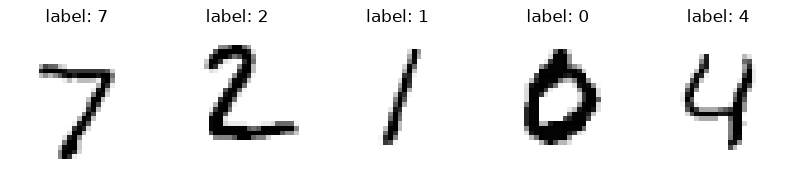

In [9]:
test_images = read_images(DATA_DIR / "t10k-images-idx3-ubyte")
test_labels = read_labels(DATA_DIR / "t10k-labels-idx1-ubyte")
test_inputs = test_images[:, np.newaxis, :, :] / 255.0

print("images:", test_images.shape, "-> network inputs:", test_inputs.shape)
plot_images(test_images[:5], test_labels[:5])

In [10]:
digit = test_inputs[0]

# the same loop as LeNet5.forward, printing each layer's output on the way
layer_names = ["pad", "C1", "S2", "C3", "S4", "C5", "flatten", "F6", "output"]
outputs = digit
print(f"{'input':>8}: {digit.shape}")
for name, layer in zip(layer_names, net.layers):
    outputs = layer.forward(outputs)
    print(f"{name:>8}: {str(outputs.shape):<14} range {outputs.min():+.4f} to {outputs.max():+.4f}")

probabilities = outputs
print("\nsame as net.forward:", np.array_equal(probabilities, net.forward(digit)))

   input: (1, 28, 28)
     pad: (1, 32, 32)    range +0.0000 to +1.0000
      C1: (6, 28, 28)    range +0.0000 to +0.2160
      S2: (6, 14, 14)    range +0.0000 to +0.2160
      C3: (16, 10, 10)   range +0.0000 to +0.0448
      S4: (16, 5, 5)     range +0.0000 to +0.0448
      C5: (120, 1, 1)    range +0.0000 to +0.0227
 flatten: (120,)         range +0.0000 to +0.0227
      F6: (84,)          range +0.0000 to +0.0046
  output: (10,)          range +0.0999 to +0.1001

same as net.forward: True


The image layers keep their last output, so the feature maps can be inspected after the pass. Below are
the six C1 maps (each kernel slid over the padded digit, then ReLU) and the six S2 maps that pool
them to half size. The kernels are random, so each map is a random mix of nearby pixels — but the
shape of the 7 survives, because a convolution only ever combines pixels that are close together.

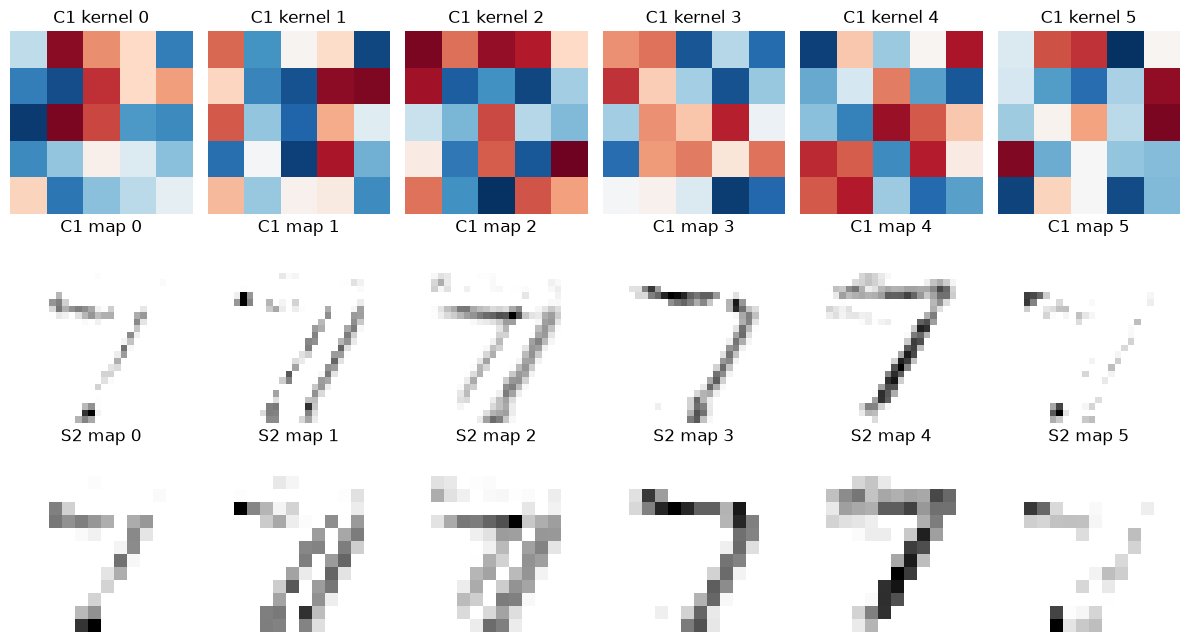

In [11]:
fig, axes = plt.subplots(3, 6, figsize=(12, 6.5))
for i in range(6):
    axes[0, i].imshow(net.c1_weights[i, 0], cmap="RdBu_r", vmin=-0.05, vmax=0.05)
    axes[0, i].set_title(f"C1 kernel {i}")
    axes[1, i].imshow(net.c1_layer.last_outputs[i], cmap="gray_r")
    axes[1, i].set_title(f"C1 map {i}")
    axes[2, i].imshow(net.s2_layer.last_outputs[i], cmap="gray_r")
    axes[2, i].set_title(f"S2 map {i}")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

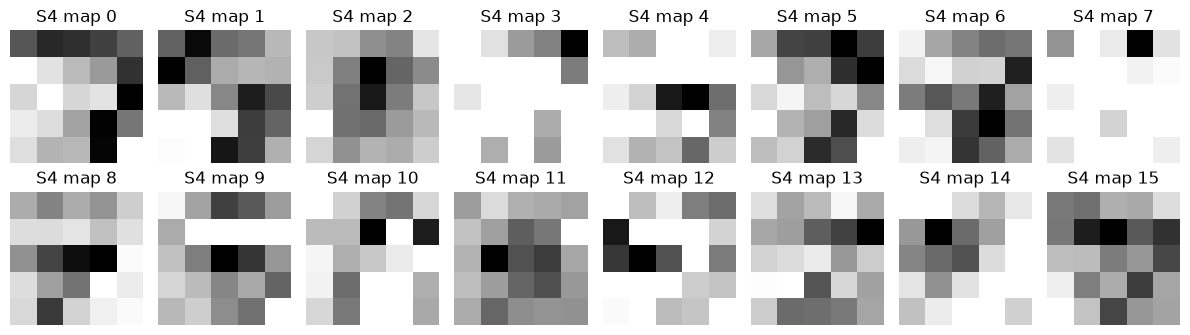

In [12]:
fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
for i, ax in enumerate(axes.flat):
    ax.imshow(net.s4_layer.last_outputs[i], cmap="gray_r")
    ax.set_title(f"S4 map {i}")
    ax.axis("off")
plt.tight_layout()
plt.show()

By S4 each map is only 5×5 and no longer looks like a digit: every value already depends on a
large part of the image. (C5's receptive field is the full 32×32 padded input.)

The output is a softmax over the ten digits:

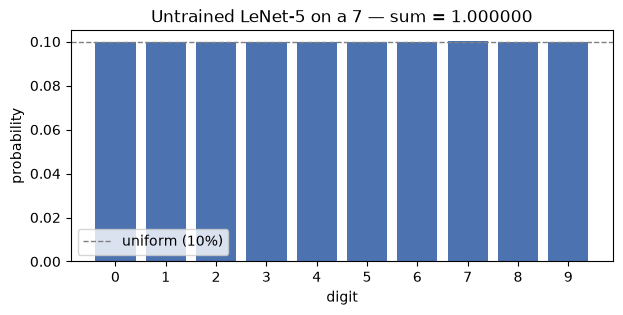

In [13]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(range(10), probabilities, color="#4c72b0")
ax.axhline(0.1, color="gray", linestyle="--", linewidth=1, label="uniform (10%)")
ax.set_xticks(range(10))
ax.set_xlabel("digit")
ax.set_ylabel("probability")
ax.set_title(f"Untrained LeNet-5 on a {test_labels[0]} — sum = {probabilities.sum():.6f}")
ax.legend()
plt.show()

With weights this small every pre-activation is close to zero, so the softmax output sits almost
exactly at 10% per digit. The untrained network has no preference — as it should.

## Predictions on test images

`forward` handles one image at a time, so the test set is scored in a loop. Without training the
accuracy should be close to chance (10%).

In [14]:
SCORED = 1000

start = time.perf_counter()
predictions = np.array([np.argmax(net.forward(image)) for image in test_inputs[:SCORED]])
elapsed = time.perf_counter() - start

accuracy = np.mean(predictions == test_labels[:SCORED])
print(f"{SCORED} images in {elapsed:.2f} s ({elapsed / SCORED * 1000:.2f} ms per image)")
print(f"accuracy: {accuracy:.1%}")
print("predicted digit counts:", np.bincount(predictions, minlength=10))

1000 images in 0.22 s (0.22 ms per image)
accuracy: 9.7%
predicted digit counts: [  0   0 221   0   0  40 107 632   0   0]


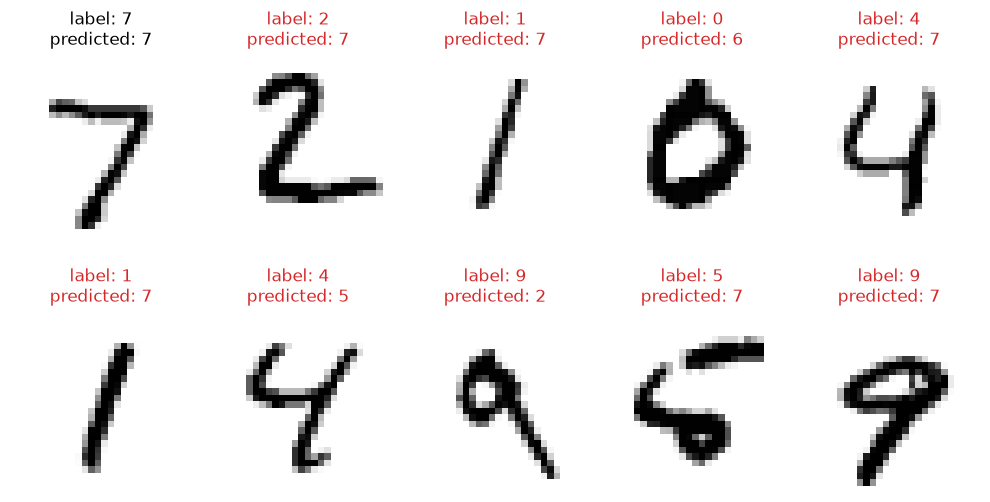

In [15]:
plot_predictions(test_images[:10], test_labels[:10], predictions[:10], columns=5)

An untrained network tends to favour one or two digits for almost every input: the near-uniform
outputs differ only by tiny amounts that depend more on the random weights than on the image.
Accuracy near 10% confirms the forward pass is not accidentally leaking labels — learning the
weights is the job of backpropagation, which comes next.

## Sanity checks — `lenet5testing`

`lenet5testing.py` is a Python port of `LeNet5Testing.java`. It runs four checks on fresh,
unseeded networks:

1. **Determinism** — the same image twice gives identical outputs.
2. **Different inputs** — two different random images give different outputs.
3. **Zero input** — an all-black image still yields a valid distribution (10 non-negative values summing to 1).
4. **Ones input** — likewise for an all-white image.

In [16]:
all_passed = lenet5testing.main()
print("\nall passed:", all_passed)

LeNet-5 Testing Suite

=== Determinism Test ===
Testing that same input produces same output...

First run output:
  Digit 0: 0.099991
  Digit 1: 0.100045
  Digit 2: 0.099949
  Digit 3: 0.099999
  Digit 4: 0.100039
  Digit 5: 0.099948
  Digit 6: 0.099971
  Digit 7: 0.100069
  Digit 8: 0.099973
  Digit 9: 0.100015

Second run output:
  Digit 0: 0.099991
  Digit 1: 0.100045
  Digit 2: 0.099949
  Digit 3: 0.099999
  Digit 4: 0.100039
  Digit 5: 0.099948
  Digit 6: 0.099971
  Digit 7: 0.100069
  Digit 8: 0.099973
  Digit 9: 0.100015

Outputs identical: True
✓ PASS: Network is deterministic

=== Different Inputs Test ===
Testing that different inputs produce different outputs...

Input 1 output:
  Digit 0: 0.100062
  Digit 1: 0.100080
  Digit 2: 0.100046
  Digit 3: 0.099925
  Digit 4: 0.100026
  Digit 5: 0.099969
  Digit 6: 0.099983
  Digit 7: 0.099973
  Digit 8: 0.099961
  Digit 9: 0.099976

Input 2 output:
  Digit 0: 0.100077
  Digit 1: 0.100085
  Digit 2: 0.100057
  Digit 3: 0.099922
  D

### Seeded networks are reproducible

The tests above build unseeded networks, so their exact numbers change from run to run. Passing the
same `seed` to `LeNet5` fixes the starting weights, which makes outputs comparable across networks:

In [17]:
same_a = LeNet5(seed=SEED).forward(digit)
same_b = LeNet5(seed=SEED).forward(digit)
other = LeNet5(seed=SEED + 1).forward(digit)

print("same seed, identical outputs:", np.array_equal(same_a, same_b))
print("different seed, max difference:", f"{np.max(np.abs(same_a - other)):.2e}")

same seed, identical outputs: True
different seed, max difference: 1.80e-04


## Summary

- `Pad`, `Conv2D`, `MaxPool2D` and `Flatten` match explicit loop computations on hand-checkable inputs.
- `windows_fast` (a strided view) gives exactly the same windows as `windows_loop` without copying the input.
- A 28×28 digit flows through LeNet-5 with the expected shapes: (1, 32, 32) → (6, 28, 28) →
  (6, 14, 14) → (16, 10, 10) → (16, 5, 5) → (120, 1, 1) → 120 → 84 → 10.
- The untrained network outputs a near-uniform softmax and scores close to chance on MNIST.
- All four `lenet5testing` checks pass: the forward pass is deterministic, sensitive to its input,
  and always returns a valid probability distribution.

Next step: backward passes for the convolution and pooling layers, so LeNet-5 can be trained.